# Forecasting permafrost active layer thickness — revisited

This notebook revisits our 2025 ASDRP project ([paper summary in the README](README.md)). The original
Prophet model concluded that active layer thickness (ALT) on Alaska's North Slope was stable or slightly
decreasing. Re-auditing the code turned up a feature-construction bug that removed all year-to-year
variation from the weather inputs, plus evaluation errors. This notebook rebuilds the pipeline and asks
three questions honestly:

1. **Is ALT actually trending?**
2. **Can we forecast next summer's ALT, and does anything beat a simple baseline?**
3. **Do the station conditions help?**

The originals are kept unchanged in [`archive/`](archive/).

In [1]:
import sys, warnings, logging
sys.path.insert(0, ".")
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").disabled = True
logging.getLogger("prophet.plot").disabled = True
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
from src.features import build_panel, load_station_winters, FEATURE_COLS
from src import backtest as B, plots
pd.set_option("display.precision", 2)

## 1. Data and features

* **ALT**: Yi & Kimball (2020), *ABoVE: Active Layer Thickness from Remote Sensing Permafrost Model,
  Alaska, 2001–2015*, ORNL DAAC, [doi:10.3334/ORNLDAAC/1760](https://doi.org/10.3334/ORNLDAAC/1760),
  filtered to the northern cluster. Note that this is itself **model output** driven by satellite data, not in-situ probing.
* **Station conditions**: Laboor (2016), *Near-surface permafrost conditions from synthesis data, 1997–2016, Alaska*,
  Arctic Permafrost Geospatial Centre. Six stations, monthly, gap-filled.

**Key constraint:** the station file only covers **September–May**; there is no summer (thaw-season) data.
So I pair each summer's ALT with the *preceding* cold season (Sep of year Y−1 to May of Y). That is the only
temporally valid pairing, and it also makes this a genuine pre-season forecast: inputs are known before thaw starts.

Station values are interpolated to each ALT site with inverse-distance weighting **computed per year** over
the stations that reported that winter. (The original code averaged across every station *and every year*,
so each site got identical features in all 15 years.)

In [2]:
panel = build_panel()
winters = load_station_winters()
print(f"{panel.site.nunique()} ALT sites, {panel.year.min()}-{panel.year.max()}, {len(panel):,} site-years")
print(f"{winters.Name.nunique()} stations, {len(winters)} station-winters with >= 6 of 9 months")
print(f"Median distance from an ALT site to its nearest station: {panel.nearest_station_km.median():.0f} km")
panel.head()

630 ALT sites, 2001-2015, 9,274 site-years
6 stations, 83 station-winters with >= 6 of 9 months
Median distance from an ALT site to its nearest station: 115 km


,year,lat,lon,alt_cm,site,snow_depth_m,air_temp_c,gst_c,gt25_c,gt50_c,gt75_c,gt100_c,n_stations,nearest_station_km
0,2001,67.02,-150.01,69,0,0.20,-17.84,-11.33,-10.43,-9.91,-9.61,-9.40,3,353.65
1,2002,67.02,-150.01,98,0,0.21,-17.57,-9.77,-9.10,-8.80,-8.60,-8.46,3,353.65
2,2003,67.02,-150.01,102,0,0.15,-16.29,-9.91,-9.18,-8.78,-8.56,-8.40,3,353.65
3,2004,67.02,-150.01,104,0,0.27,-18.24,-9.89,-9.29,-8.94,-8.73,-8.53,4,353.65
4,2005,67.02,-150.01,138,0,0.16,-16.58,-10.71,-10.05,-9.54,-9.26,-9.01,5,353.65


In [3]:
# Sanity check the fix: features now vary within a site over time
within = panel.groupby("site")[FEATURE_COLS].std().median()
print("Median within-site std of each feature (was exactly 0 in the original):")
within.round(3)

Median within-site std of each feature (was exactly 0 in the original):


snow_depth_m    0.05
air_temp_c      1.31
gst_c           1.10
gt25_c          1.02
gt50_c          0.99
gt75_c          0.81
gt100_c         0.78
dtype: float64

Most of the variation in ALT is **between sites**, not between years, which already hints that a site's own
history will be a strong forecaster:

In [4]:
site_share = panel.groupby("site").alt_cm.transform("mean").var() / panel.alt_cm.var()
print(f"Share of ALT variance explained by site identity alone: {site_share:.0%}")

Share of ALT variance explained by site identity alone: 72%


## 2. Is ALT trending?

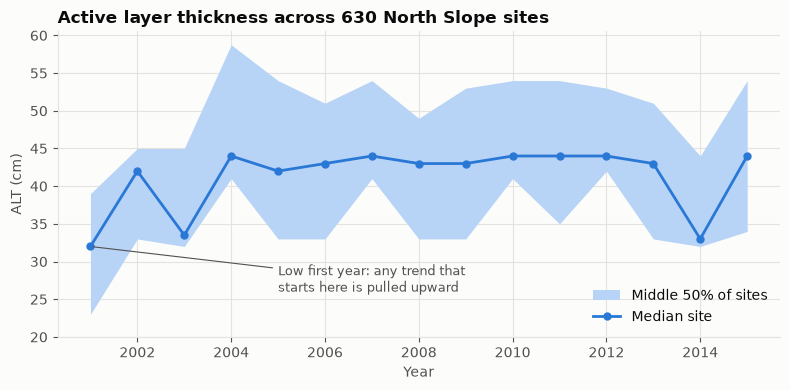

In [5]:
plots.regional_alt(panel, "figures/regional_alt.png");

A site fixed-effects regression (`ALT ~ year + site`, standard errors clustered by site) gives the average
within-site trend. The answer depends heavily on where the window starts, because 2001 is the first and one of the lowest years:

,start_year,slope,lo,hi
0,2001,0.65,0.55,0.75
1,2002,0.28,0.18,0.37
2,2004,-0.34,-0.47,-0.20
3,2006,-0.04,-0.16,0.08


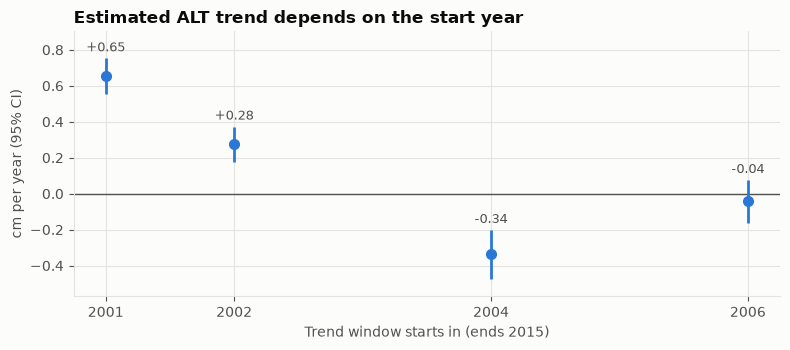

In [6]:
rows = []
for start in [2001, 2002, 2004, 2006]:
    q = panel[panel.year >= start]
    fit = smf.ols("alt_cm ~ year + C(site)", q).fit(cov_type="cluster", cov_kwds={"groups": q.site})
    lo, hi = fit.conf_int().loc["year"]
    rows.append(dict(start_year=start, slope=fit.params.year, lo=lo, hi=hi))
trend = pd.DataFrame(rows)
plots.trend_by_start(trend, "figures/trend_by_start.png")
trend

**Finding:** there is no robust trend. Including 2001 gives about +0.65 cm/yr; starting in 2004 gives a small
*negative* trend; starting in 2006 gives essentially zero. Fifteen years of a model-derived product is too short to
separate a climate signal from a few anomalous years (2001, 2003 and 2014 are all low). The paper's conclusion ("stable or slightly decreasing") roughly
matches 2004–2015, but it came from a model whose inputs couldn't express any year-to-year change, so it wasn't
actually tested.

## 3. Forecasting: rolling-origin backtest

For each test year T from 2008 to 2015, every model is fit only on years before T and predicts each site's ALT in
year T. Winter features for year T are allowed because they're observed before the thaw season.

| Model | What it does |
|---|---|
| Persistence | last observed ALT at the site |
| Site mean | the site's average over all training years |
| Site mean + trend | site fixed effect + common linear trend (ridge) |
| … + winter features | adds the 7 interpolated winter variables |
| Gradient boosting | site mean, last value, location, year, winter features |
| Prophet, pooled | the paper's setup with the feature bug fixed: one Prophet over all sites |
| Prophet on regional anomaly | Prophet on the regional mean anomaly, added to each site's mean |

,MAE,RMSE,Bias
model,,,
Site mean,5.89,14.34,-2.15
Persistence (last year),6.68,17.73,0.48
Gradient boosting,7.99,17.06,2.08
Site mean + trend,9.49,15.92,6.58
Site mean + trend + winter features,12.86,18.11,10.36
Prophet on regional anomaly,12.94,18.67,3.93
"Prophet, pooled (paper setup, fixed)",19.25,31.40,1.82


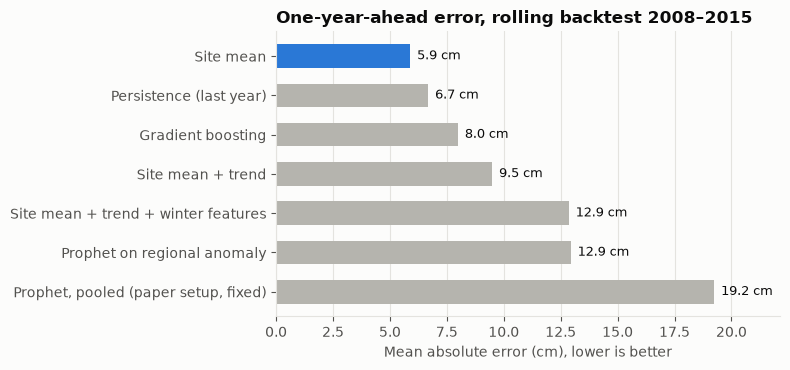

In [7]:
preds = B.rolling_backtest(panel)
scores = B.score(preds).sort_values("MAE")
plots.backtest_bars(scores, best=scores.index[0], path="figures/backtest_mae.png")
scores

In [8]:
# Error by test year (MAE, cm)
preds.assign(ae=(preds.yhat - preds.y).abs()).pivot_table(index="year", columns="model", values="ae").round(1)

model,Gradient boosting,Persistence (last year),Prophet on regional anomaly,"Prophet, pooled (paper setup, fixed)",Site mean,Site mean + trend,Site mean + trend + winter features
year,,,,,,,
2008,5.9,10.5,5.1,29.8,5.2,14.8,15.5
2009,11.2,5.2,10.3,15.4,4.3,11.7,11.6
2010,8.9,8.8,19.7,16.8,8.8,6.4,15.1
2011,6.4,4.2,20.0,18.1,6.2,8.0,5.6
2012,8.5,4.5,9.4,28.0,6.2,6.5,15.3
2013,6.6,5.7,4.7,15.0,4.4,10.4,9.4
2014,7.7,4.9,19.9,15.6,6.2,12.6,19.7
2015,8.8,9.7,14.5,15.3,5.7,5.3,10.8


**Finding:** the **site mean wins** (MAE ≈ 5.9 cm). Every model with a trend over-forecasts, because the trend
learned from the 2001 jump keeps extrapolating into flat years (see the positive bias). The paper's pooled Prophet
setup, even with the bug fixed, is about **3× worse** than the baseline: pooling 630 sites into one series throws away
the between-site differences that make up most of the variance.

### The paper's original split
For comparison with the paper (train 2001–2011, predict 2012–2015, a 1–4 year horizon):

In [9]:
tr, te = panel[panel.year < 2012], panel[panel.year >= 2012]
res = {}
for name, fn in B.MODELS.items():
    e = fn(tr, te).values - te.alt_cm.values
    res[name] = dict(MAE=np.abs(e).mean(), RMSE=np.sqrt((e ** 2).mean()))
pd.DataFrame(res).T.sort_values("MAE")

,MAE,RMSE
Site mean,5.64,13.54
Persistence (last year),5.85,15.97
Gradient boosting,7.49,17.23
Site mean + trend,11.79,16.82
Prophet on regional anomaly,17.92,23.46
Site mean + trend + winter features,19.24,22.36
"Prophet, pooled (paper setup, fixed)",22.15,29.02


The original notebook reported "RMSE 773, MAE 19.3". The 773 was actually the MSE (no square root), and both
numbers were computed after a many-to-many merge on year alone, which paired every site's prediction with every
other site's observation. Correctly computed, the paper's setup scores ~22 cm MAE on this split versus ~5.6 cm for the site mean.

## 4. Do the winter conditions carry signal?

Fitting the within-site model on all data with a small, less collinear feature set (the 4 ground-temperature
depths are almost perfectly correlated with each other):

In [10]:
few = ["snow_depth_m", "air_temp_c", "gt50_c"]
d = panel.copy()
cols = ["alt_cm"] + few
d[cols] = d[cols] - d.groupby("site")[cols].transform("mean")   # within-site anomalies
fe = smf.ols("alt_cm ~ " + " + ".join(few) + " - 1", d).fit(cov_type="cluster", cov_kwds={"groups": d.site})
print(f"Within-site R^2: {fe.rsquared:.3f}")
fe.summary().tables[1]

Within-site R^2: 0.008


,coef,std err,z,P>|z|,[0.025,0.975]
snow_depth_m,24.4138,5.473,4.461,0.000,13.687,35.140
air_temp_c,0.6634,0.203,3.265,0.001,0.265,1.062
gt50_c,0.1448,0.341,0.424,0.672,-0.524,0.814


The signs are now physically sensible: deeper winter snow (which insulates the ground) and warmer winters go with
a deeper active layer next summer (+~24 cm per metre of snow, +~0.7 cm per °C of winter air temperature; the 50 cm
ground temperature adds nothing once those are in). The original model reported the opposite sign for air temperature,
which was an artifact of the bug. Two caveats: with six stations the interpolated features are close to region-wide, so
there are effectively only ~14 independent winters and the p-values are optimistic; and the features explain **under 1%**
of within-site variation. Adding them **hurts** out-of-sample accuracy. That's expected: ALT is set mostly by *summer* thaw, which isn't in the data.

## 5. Conclusions and what I'd do next

* **No robust ALT trend** in 2001–2015 for this region; the sign flips with the start year.
* **A per-site climatology beats every model tried**, including the paper's Prophet setup (≈5.9 vs ≈19 cm MAE).
  Any future model should be reported as skill relative to that baseline.
* **Winter conditions are weak predictors** (right sign, tiny effect). The missing piece is summer forcing.

Next steps, in order of expected value:
1. Add summer thaw-degree-days (e.g. ERA5-Land or the stations' Jun–Aug records) — the main physical driver.
2. Use in-situ ALT (CALM network) as the target, or at least validate against it, since the current target is itself model output.
3. Extend past 2015 with the newer ABoVE ALT products so trends aren't hostage to one year.
4. Then try hierarchical models (partial pooling across sites) or foundation models like TimesFM, scored against the site-mean baseline.